# 05 — Provisional SER model comparison

## Research objective
Compare regression models for a **provisional right-eye spherical equivalent refraction (SER)** outcome in the `2018` sheet of `DATA.xls`. SER is calculated as `sphere + cylinder / 2`, using the audited columns `spherical refraction of right eye` and `cylindrical refraction of right eye`. The formula assumes the sphere and cylinder values use a compatible refraction convention, refer to the same eye/examination, and have not been transformed in an undocumented way. Those assumptions have not been verified from a source codebook or protocol. Results therefore describe prediction of a constructed candidate outcome; they are not clinical validation.

The eight candidate predictors are the audited fields `gender`, `height`, `weight`, `axial length of right eye`, `time of study at weekdays`, `time of study at weekend days`, `time outdoors at weekdays`, and `time outdoors at weekend days`. Units, gender coding, and measurement timing are undocumented. Sphere, cylinder, axis, direct SER fields, IDs, and outcome-derived classes are excluded. No other datasets are merged.

We retain all rows, including unusual values. The audit found no missing observations or exact duplicate records in the selected 2018 fields. Sphere `-1` and `-9` and cylinder `-1` values are retained because their sentinel status is unverified. No IQR-flagged or other observations are excluded. This notebook is an exploratory predictive analysis only.

## Analysis plan
Use one random 80:20 train/test split (`random_state=42`). Compare Dummy, Linear Regression, Random Forest, XGBoost, Gradient Boosting, RBF-SVR, and Extra Trees with the same split. Use five-fold CV on training data. For the two tuned models, use nested five-fold CV (inner randomized search confined to each outer training fold) for a less biased CV estimate, then tune final hyperparameters with five-fold `RandomizedSearchCV` on the full training partition. The test partition is not used for tuning or model selection. The prespecified primary model for interpretation is tuned XGBoost; Random Forest is the main comparison. No early stopping is used, so the held-out test set is never used for early stopping.

Preprocessing is part of each sklearn `Pipeline` and is fit inside folds: gender is treated as a nominal categorical field and one-hot encoded; remaining predictors are numeric with median imputation. SVR additionally standard-scales numeric predictors. The dataset has no participant identifier, so participant-level splitting cannot be verified; this is a limitation.

In [1]:
from pathlib import Path
import shutil, subprocess, tempfile, warnings, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, xgboost, shap
from scipy.stats import randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR
from xgboost import XGBRegressor
import joblib

SEED=42
ROOT=Path.cwd()
if not (ROOT/"DATA.xls").exists(): ROOT=ROOT.parent
RESULTS=ROOT/"outputs"/"results"; RESULTS.mkdir(parents=True,exist_ok=True)
MODELS=ROOT/"outputs"/"models"; MODELS.mkdir(parents=True,exist_ok=True)
FIGURES=ROOT/"outputs"/"figures"; FIGURES.mkdir(parents=True,exist_ok=True)
print({"scikit_learn":sklearn.__version__,"xgboost":xgboost.__version__,"shap":shap.__version__})

{'scikit_learn': '1.7.2', 'xgboost': '3.3.0', 'shap': '0.52.0'}


In [2]:
# Load only the 2018 sheet. Convert the legacy workbook in a temporary directory if needed.
try:
    data=pd.read_excel(ROOT/"DATA.xls",sheet_name="2018")
except ImportError:
    soffice=shutil.which("soffice") or "/Users/omvdangi/.cache/codex-runtimes/codex-primary-runtime/dependencies/bin/override/soffice"
    temp=Path(tempfile.mkdtemp(prefix="myopia_model_"))
    subprocess.run([soffice,"--headless","--convert-to","xlsx","--outdir",str(temp),str(ROOT/"DATA.xls")],check=True,capture_output=True,text=True)
    data=pd.read_excel(temp/"DATA.xlsx",sheet_name="2018")

target_sphere="spherical refraction of right eye"
target_cylinder="cylindrical refraction of right eye"
feature_columns=["gender","height","weight","axial length of right eye",
                 "time of study at weekdays","time of study at weekend days",
                 "time outdoors at weekdays","time outdoors at weekend days"]
required=[target_sphere,target_cylinder]+feature_columns
missing_columns=[c for c in required if c not in data.columns]
if missing_columns: raise KeyError(f"Required audited columns missing: {missing_columns}")
# Validate numeric parseability without recoding sentinel-looking or extreme values.
parsed=data[required].apply(pd.to_numeric,errors="coerce")
if parsed.isna().any().any():
    raise ValueError("At least one target component or predictor is missing/non-numeric. Review records before training; no rows were silently dropped.")
X=parsed[feature_columns].copy()
# Gender is a nominal coded field of unknown meaning; keep its observed categories categorical.
X["gender"]=X["gender"].astype("string")
y=(parsed[target_sphere]+parsed[target_cylinder]/2).rename("provisional_right_eye_SER")

quality={"n_rows":len(data),"exact_duplicate_rows_retained":int(data.duplicated().sum()),
         "missing_cells_in_required_fields":int(parsed.isna().sum().sum()),
         "sphere_min":float(parsed[target_sphere].min()),"sphere_max":float(parsed[target_sphere].max()),
         "cylinder_min":float(parsed[target_cylinder].min()),"cylinder_max":float(parsed[target_cylinder].max()),
         "candidate_SER_min":float(y.min()),"candidate_SER_max":float(y.max()),
         "sphere_minus1_count":int((parsed[target_sphere]==-1).sum()),"sphere_minus9_count":int((parsed[target_sphere]==-9).sum()),
         "cylinder_minus1_count":int((parsed[target_cylinder]==-1).sum()),
         "rows_excluded":0,"ser_formula":"sphere + cylinder / 2","target_status":"provisional; source refraction convention unverified"}
display(pd.Series(quality,name="2018 data quality review"))
pd.DataFrame([quality]).to_csv(RESULTS/"provisional_ser_data_quality.csv",index=False)
# Audit-oriented IQR flag counts only; no observation is removed.
flags=[]
for col in [target_sphere,target_cylinder,"height","weight","axial length of right eye"]:
    values=parsed[col]; q1,q3=values.quantile([.25,.75]); iqr=q3-q1
    flags.append({"column":col,"iqr_flag_count":int(((values<q1-1.5*iqr)|(values>q3+1.5*iqr)).sum()),"action":"retained; review flag is not an invalidity determination"})
pd.DataFrame(flags).to_csv(RESULTS/"outlier_review_flags.csv",index=False)
display(pd.DataFrame(flags))

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=SEED,shuffle=True)
print(f"Training rows: {len(X_train)}; test rows: {len(X_test)}; split seed: {SEED}")

n_rows                                                                           3658
exact_duplicate_rows_retained                                                       0
missing_cells_in_required_fields                                                    0
sphere_min                                                                      -14.0
sphere_max                                                                       8.25
cylinder_min                                                                     -5.0
cylinder_max                                                                      0.0
candidate_SER_min                                                              -15.75
candidate_SER_max                                                               7.125
sphere_minus1_count                                                               118
sphere_minus9_count                                                                 3
cylinder_minus1_count                                 

,column,iqr_flag_count,action
0,spherical refraction of right eye,108,retained; review flag is not an invalidity det...
1,cylindrical refraction of right eye,257,retained; review flag is not an invalidity det...
2,height,0,retained; review flag is not an invalidity det...
3,weight,19,retained; review flag is not an invalidity det...
4,axial length of right eye,41,retained; review flag is not an invalidity det...


Training rows: 2926; test rows: 732; split seed: 42


## Preprocessing and candidate estimators
All model preprocessing is inside a pipeline, ensuring each fold fits its imputer/encoder/scaler only on that fold's training subset. No target imputation is performed. Since all selected fields parsed completely in the audited sheet, the imputers are safeguards rather than a source of filled values in this particular run.

In [3]:
categorical_features=["gender"]
numeric_features=[c for c in feature_columns if c not in categorical_features]
def make_preprocessor(scale_numeric=False):
    num_steps=[("imputer",SimpleImputer(strategy="median"))]
    if scale_numeric: num_steps.append(("scaler",StandardScaler()))
    num_pipe=Pipeline(num_steps)
    cat_pipe=Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),
                       ("onehot",OneHotEncoder(handle_unknown="ignore",sparse_output=False))])
    return ColumnTransformer([("numeric",num_pipe,numeric_features),("categorical",cat_pipe,categorical_features)],remainder="drop")
def make_pipeline(estimator,scale_numeric=False):
    return Pipeline([("preprocess",make_preprocessor(scale_numeric)),("model",estimator)])

def xgb_estimator(**kwargs):
    return XGBRegressor(objective="reg:squarederror",eval_metric="mae",random_state=SEED,n_jobs=1,verbosity=0,**kwargs)

fixed_models={
 "Dummy Regressor":make_pipeline(DummyRegressor(strategy="mean")),
 "Linear Regression":make_pipeline(LinearRegression()),
 "Gradient Boosting":make_pipeline(GradientBoostingRegressor(random_state=SEED)),
 "SVR (RBF)":make_pipeline(SVR(kernel="rbf"),scale_numeric=True),
 "Extra Trees":make_pipeline(ExtraTreesRegressor(n_estimators=400,min_samples_leaf=1,n_jobs=-1,random_state=SEED))}
rf_space={
 "model__n_estimators":[200,400,600],
 "model__max_depth":[None,10,20,30],
 "model__min_samples_split":[2,5,10],
 "model__min_samples_leaf":[1,2,4],
 "model__max_features":[1.0,"sqrt",0.7]}
xgb_space={
 "model__n_estimators":[200,400,600,800],
 "model__max_depth":[2,3,4,5,6],
 "model__learning_rate":[0.02,0.03,0.05,0.08,0.10],
 "model__subsample":[0.70,0.85,1.0],
 "model__colsample_bytree":[0.70,0.85,1.0],
 "model__min_child_weight":[1,3,5],
 "model__reg_alpha":[0.0,0.01,0.1,1.0],
 "model__reg_lambda":[0.1,1.0,5.0,10.0]}
def make_rf(): return make_pipeline(RandomForestRegressor(random_state=SEED,n_jobs=1))
def make_xgb(): return make_pipeline(xgb_estimator())
print("XGB search parameters:",list(xgb_space))

XGB search parameters: ['model__n_estimators', 'model__max_depth', 'model__learning_rate', 'model__subsample', 'model__colsample_bytree', 'model__min_child_weight', 'model__reg_alpha', 'model__reg_lambda']


## Training-only cross-validation and hyperparameter tuning
For tuned Random Forest and XGBoost, outer five-fold CV estimates performance on held-out training folds; each outer fold performs its own three-fold randomized search using only the outer-fold training portion. The final randomized search for each model then uses five-fold CV on the full 80% training partition. Search scoring is negative MAE. The 20% test partition is untouched until evaluation below.

In [4]:
outer_cv=KFold(n_splits=5,shuffle=True,random_state=SEED)
inner_cv=KFold(n_splits=3,shuffle=True,random_state=SEED)
cv_records=[]
# Five-fold CV for fixed model specifications.
for name,pipe in fixed_models.items():
    fold_neg_mae=cross_val_score(pipe,X_train,y_train,cv=outer_cv,scoring="neg_mean_absolute_error",n_jobs=1)
    cv_records.append({"Model":name,"CV_MAE_mean":float(-fold_neg_mae.mean()),"CV_MAE_std":float(fold_neg_mae.std(ddof=1)),"CV_fold_MAE":[float(-v) for v in fold_neg_mae]})
    print(name,"5-fold CV MAE:",round(-fold_neg_mae.mean(),4),"±",round(fold_neg_mae.std(ddof=1),4))

def nested_tuned_cv(name,pipe_factory,param_space,n_iter=8):
    fold_mae=[]
    for fold,(tr_idx,va_idx) in enumerate(outer_cv.split(X_train),start=1):
        search=RandomizedSearchCV(pipe_factory(),param_distributions=param_space,n_iter=n_iter,scoring="neg_mean_absolute_error",
                                  cv=inner_cv,random_state=SEED+fold,n_jobs=2,refit=True,verbose=0)
        search.fit(X_train.iloc[tr_idx],y_train.iloc[tr_idx])
        pred=search.predict(X_train.iloc[va_idx])
        fold_mae.append(mean_absolute_error(y_train.iloc[va_idx],pred))
        print(f"{name} nested outer fold {fold}/5 MAE={fold_mae[-1]:.4f}")
    cv_records.append({"Model":name,"CV_MAE_mean":float(np.mean(fold_mae)),"CV_MAE_std":float(np.std(fold_mae,ddof=1)),"CV_fold_MAE":[float(v) for v in fold_mae]})
    return fold_mae

rf_nested=nested_tuned_cv("Random Forest Regressor",make_rf,rf_space,n_iter=8)
xgb_nested=nested_tuned_cv("XGBoost Regressor",make_xgb,xgb_space,n_iter=8)

# Final tuning on the full training partition only; no access to X_test or y_test.
rf_search=RandomizedSearchCV(make_rf(),rf_space,n_iter=20,scoring="neg_mean_absolute_error",cv=KFold(5,shuffle=True,random_state=SEED),
                             random_state=SEED,n_jobs=2,refit=True,verbose=1)
xgb_search=RandomizedSearchCV(make_xgb(),xgb_space,n_iter=24,scoring="neg_mean_absolute_error",cv=KFold(5,shuffle=True,random_state=SEED),
                              random_state=SEED,n_jobs=2,refit=True,verbose=1)
rf_search.fit(X_train,y_train); xgb_search.fit(X_train,y_train)
print("RF best training-CV MAE:",round(-rf_search.best_score_,4),"best params:",rf_search.best_params_)
print("XGB best training-CV MAE:",round(-xgb_search.best_score_,4),"best params:",xgb_search.best_params_)
pd.DataFrame([{"model":"Random Forest Regressor","best_training_cv_mae":-rf_search.best_score_,"best_params":json.dumps(rf_search.best_params_)},
              {"model":"XGBoost Regressor","best_training_cv_mae":-xgb_search.best_score_,"best_params":json.dumps(xgb_search.best_params_)}]).to_csv(RESULTS/"ser_hyperparameter_search.csv",index=False)

Dummy Regressor 5-fold CV MAE: 1.8388 ± 0.047
Linear Regression 5-fold CV MAE: 1.0155 ± 0.0395


Gradient Boosting 5-fold CV MAE: 0.909 ± 0.0366


SVR (RBF) 5-fold CV MAE: 0.9376 ± 0.0476


Extra Trees 5-fold CV MAE: 0.9465 ± 0.039


Random Forest Regressor nested outer fold 1/5 MAE=0.9162


...

XGBoost Regressor nested outer fold 3/5 MAE=0.8281


XGBoost Regressor nested outer fold 4/5 MAE=0.9321


XGBoost Regressor nested outer fold 5/5 MAE=0.9224
Fitting 5 folds for each of 20 candidates, totalling 100 fits


Fitting 5 folds for each of 24 candidates, totalling 120 fits


RF best training-CV MAE: 0.9097 best params: {'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': 0.7, 'model__max_depth': 10}
XGB best training-CV MAE: 0.8999 best params: {'model__subsample': 0.7, 'model__reg_lambda': 1.0, 'model__reg_alpha': 1.0, 'model__n_estimators': 400, 'model__min_child_weight': 5, 'model__max_depth': 4, 'model__learning_rate': 0.02, 'model__colsample_bytree': 0.85}


In [5]:
# Assemble final estimators and evaluate once on the untouched test partition.
final_models={**fixed_models,"Random Forest Regressor":rf_search.best_estimator_,"XGBoost Regressor":xgb_search.best_estimator_}
# Train fixed estimators on all training data. Tuned searches were refit on X_train by RandomizedSearchCV.
for name,model in final_models.items():
    if name not in ["Random Forest Regressor","XGBoost Regressor"]: model.fit(X_train,y_train)

cv_by_model={r["Model"]:r for r in cv_records}
comparison=[]
test_predictions={}
for name,model in final_models.items():
    pred=model.predict(X_test); test_predictions[name]=pred
    mse=mean_squared_error(y_test,pred)
    comparison.append({"Model":name,"Cross-validation MAE mean (D)":cv_by_model[name]["CV_MAE_mean"],
                       "Cross-validation MAE standard deviation (D)":cv_by_model[name]["CV_MAE_std"],
                       "Test MAE (D)":mean_absolute_error(y_test,pred),"Test MSE (D^2)":mse,
                       "Test RMSE (D)":math.sqrt(mse),"Test R2":r2_score(y_test,pred)})
comparison=pd.DataFrame(comparison).sort_values("Test MAE (D)").reset_index(drop=True)
comparison.to_csv(RESULTS/"model_comparison.csv",index=False)
display(comparison)
# Save the requested fitted, preprocessed pipelines.
joblib.dump(final_models["XGBoost Regressor"],MODELS/"xgboost_ser_model.joblib")
joblib.dump(final_models["Random Forest Regressor"],MODELS/"random_forest_ser_model.joblib")
print("Saved tuned pipelines to:",MODELS/"xgboost_ser_model.joblib","and",MODELS/"random_forest_ser_model.joblib")

,Model,Cross-validation MAE mean (D),Cross-validation MAE standard deviation (D),Test MAE (D),Test MSE (D^2),Test RMSE (D),Test R2
0,XGBoost Regressor,0.903704,0.042803,0.910606,1.617158,1.271675,0.690209
1,Gradient Boosting,0.908954,0.036568,0.914110,1.629442,1.276496,0.687856
2,Random Forest Regressor,0.910855,0.048410,0.917672,1.639771,1.280535,0.685877
3,SVR (RBF),0.937645,0.047643,0.924191,1.740832,1.319406,0.666517
4,Extra Trees,0.946532,0.039018,0.943759,1.705217,1.305839,0.673340
5,Linear Regression,1.015510,0.039491,1.010635,1.750627,1.323113,0.664641
6,Dummy Regressor,1.838794,0.047025,1.844874,5.227303,2.286330,-0.001369


Saved tuned pipelines to: /Users/omvdangi/Desktop/Myopia/outputs/models/xgboost_ser_model.joblib and /Users/omvdangi/Desktop/Myopia/outputs/models/random_forest_ser_model.joblib


## Test-set diagnostic visualizations
The test partition is used here for final performance and diagnostic plots only. No hyperparameter choice is changed based on these plots or results. The reported empirical lowest test MAE is descriptive; it is not used to retroactively select or tune a model. XGBoost was prespecified for model interpretation.

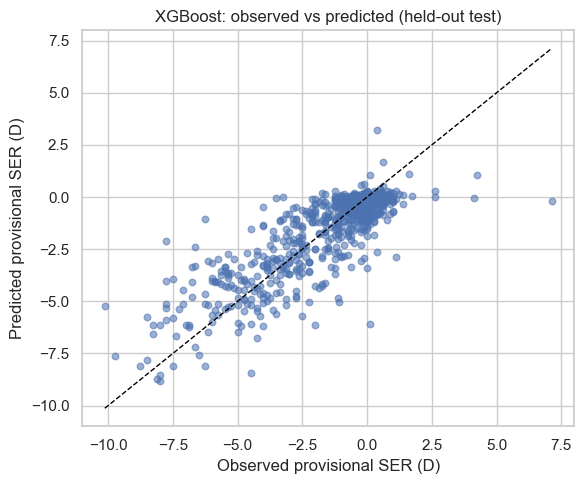

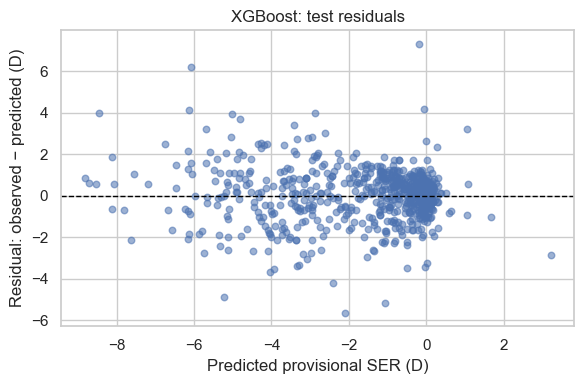

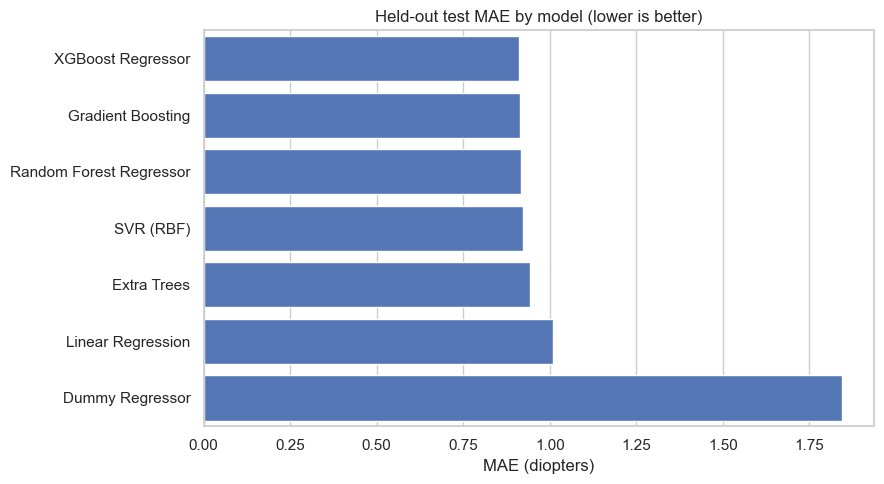

In [6]:
sns.set_theme(style="whitegrid",context="notebook")
# Actual versus predicted for prespecified primary XGBoost model.
pred_xgb=test_predictions["XGBoost Regressor"]; residual=y_test.to_numpy()-pred_xgb
fig,ax=plt.subplots(figsize=(6,5)); ax.scatter(y_test,pred_xgb,alpha=.55,s=22)
lo=min(y_test.min(),pred_xgb.min()); hi=max(y_test.max(),pred_xgb.max()); ax.plot([lo,hi],[lo,hi],"--",color="black",linewidth=1)
ax.set(xlabel="Observed provisional SER (D)",ylabel="Predicted provisional SER (D)",title="XGBoost: observed vs predicted (held-out test)")
fig.tight_layout(); fig.savefig(FIGURES/"xgboost_actual_vs_predicted.png",dpi=220,bbox_inches="tight"); plt.show(); plt.close(fig)
fig,ax=plt.subplots(figsize=(6,4)); ax.scatter(pred_xgb,residual,alpha=.55,s=22); ax.axhline(0,color="black",linestyle="--",linewidth=1)
ax.set(xlabel="Predicted provisional SER (D)",ylabel="Residual: observed − predicted (D)",title="XGBoost: test residuals")
fig.tight_layout(); fig.savefig(FIGURES/"xgboost_residuals.png",dpi=220,bbox_inches="tight"); plt.show(); plt.close(fig)
fig,ax=plt.subplots(figsize=(9,5)); comp_plot=comparison.sort_values("Test MAE (D)")
sns.barplot(data=comp_plot,x="Test MAE (D)",y="Model",ax=ax,color="#4472C4"); ax.set(title="Held-out test MAE by model (lower is better)",xlabel="MAE (diopters)",ylabel="")
fig.tight_layout(); fig.savefig(FIGURES/"model_test_performance.png",dpi=220,bbox_inches="tight"); plt.show(); plt.close(fig)

## Permutation importance and SHAP for prespecified XGBoost
Permutation importance measures how much held-out score changes when one input field is shuffled. It is predictive reliance under this evaluation distribution, not causal effect. Correlated features can share or mask importance. SHAP is an additive explanation of this fitted model's predictions relative to a background distribution; it is not evidence that a feature causes refraction.

,feature,permutation_importance_mean,permutation_importance_std
3,axial length of right eye,1.161553,0.048979
0,gender,0.056315,0.008730
1,height,0.049585,0.010133
4,time of study at weekdays,0.013813,0.007577
2,weight,0.005017,0.005379
7,time outdoors at weekend days,0.002529,0.002907
5,time of study at weekend days,0.001494,0.002569
6,time outdoors at weekdays,-0.006544,0.001908


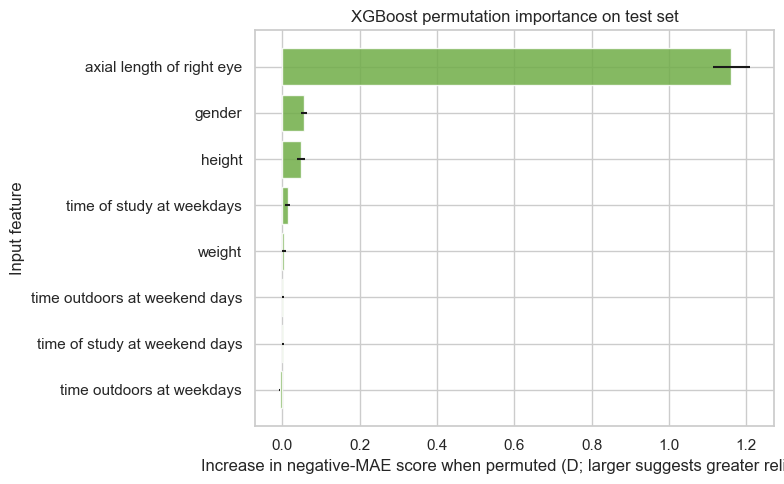

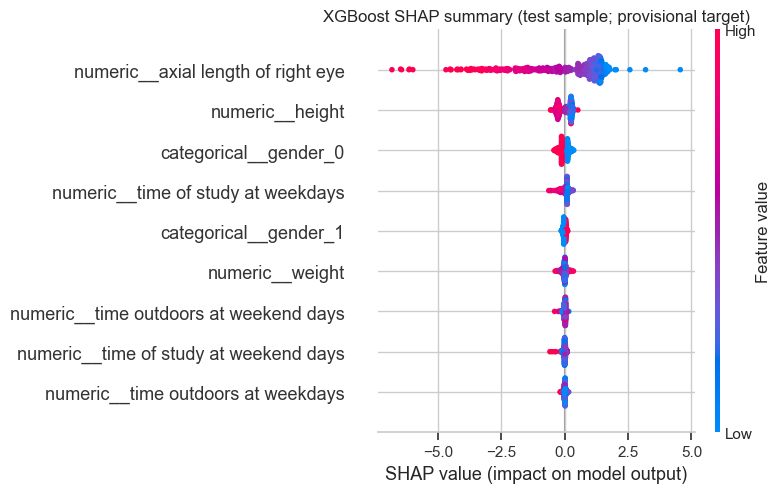

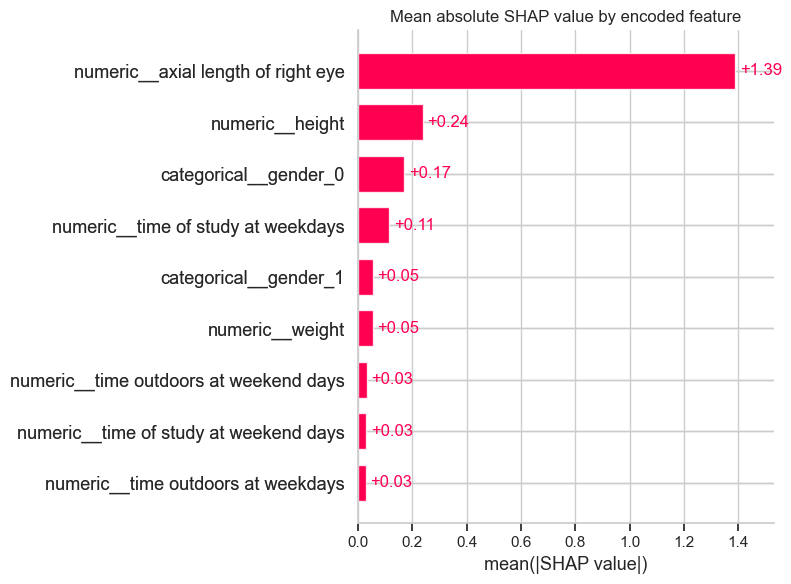

SHAP status: success


In [7]:
primary_model=final_models["XGBoost Regressor"]
perm=permutation_importance(primary_model,X_test,y_test,n_repeats=20,random_state=SEED,scoring="neg_mean_absolute_error",n_jobs=2)
importance=pd.DataFrame({"feature":feature_columns,"permutation_importance_mean":perm.importances_mean,"permutation_importance_std":perm.importances_std}).sort_values("permutation_importance_mean",ascending=False)
importance.to_csv(RESULTS/"xgboost_permutation_importance.csv",index=False)
display(importance)
fig,ax=plt.subplots(figsize=(8,5)); plot_imp=importance.sort_values("permutation_importance_mean")
ax.barh(plot_imp.feature,plot_imp.permutation_importance_mean,xerr=plot_imp.permutation_importance_std,color="#70AD47",alpha=.85)
ax.set(xlabel="Increase in negative-MAE score when permuted (D; larger suggests greater reliance)",ylabel="Input feature",title="XGBoost permutation importance on test set")
fig.tight_layout(); fig.savefig(FIGURES/"xgboost_permutation_importance.png",dpi=220,bbox_inches="tight"); plt.show(); plt.close(fig)

# SHAP is optional and may fail because of installed package/version interactions; preserve permutation results either way.
shap_status="not attempted"
try:
    pre=primary_model.named_steps["preprocess"]
    tree=primary_model.named_steps["model"]
    x_trans=pre.transform(X_test)
    names=pre.get_feature_names_out()
    n_sample=min(500,len(X_test)); x_sample=pd.DataFrame(x_trans[:n_sample],columns=names)
    explainer=shap.TreeExplainer(tree)
    shap_values=explainer(x_sample)
    shap_status="success"
    plt.figure(); shap.plots.beeswarm(shap_values,show=False,max_display=12)
    plt.title("XGBoost SHAP summary (test sample; provisional target)")
    plt.tight_layout(); plt.savefig(FIGURES/"xgboost_shap_summary.png",dpi=220,bbox_inches="tight"); plt.show(); plt.close()
    plt.figure(); shap.plots.bar(shap_values,show=False,max_display=12)
    plt.title("Mean absolute SHAP value by encoded feature")
    plt.tight_layout(); plt.savefig(FIGURES/"xgboost_shap_importance.png",dpi=220,bbox_inches="tight"); plt.show(); plt.close()
except Exception as exc:
    shap_status=f"unavailable: {type(exc).__name__}: {exc}"
    print("SHAP could not be generated; no SHAP result is claimed.",shap_status)
pd.DataFrame([{"status":shap_status,"interpretation_note":"SHAP values explain model predictions; they are not causal effects."}]).to_csv(RESULTS/"xgboost_shap_status.csv",index=False)
print("SHAP status:",shap_status)

In [8]:
# Final summary: XGBoost is the prespecified model for interpretation; best observed test MAE is reported descriptively.
best_test=comparison.iloc[0]
xgb_row=comparison.loc[comparison["Model"]=="XGBoost Regressor"].iloc[0]
print("FINAL RESEARCH SUMMARY")
print(f"Best observed test MAE: {best_test['Model']} — {best_test['Test MAE (D)']:.4f} D; RMSE {best_test['Test RMSE (D)']:.4f} D; R² {best_test['Test R2']:.4f}.")
print(f"Prespecified XGBoost: CV MAE {xgb_row['Cross-validation MAE mean (D)']:.4f} ± {xgb_row['Cross-validation MAE standard deviation (D)']:.4f} D; test MAE {xgb_row['Test MAE (D)']:.4f} D, RMSE {xgb_row['Test RMSE (D)']:.4f} D, R² {xgb_row['Test R2']:.4f}.")
print("Top permutation features:",", ".join(importance.head(3).feature.tolist()))
print("Interpretation: predictive importance reflects this fitted model and dataset only; it does not establish causal relationships.")
print("Limitations: target remains provisional because the refraction convention/protocol is undocumented; predictor units/coding/timing are unverified; no participant IDs are available to rule out repeated people; no independent cohort validation was performed. Results must not be presented as clinical validation.")
print("No rows were excluded and no -1/-9 values were recoded as missing.")

FINAL RESEARCH SUMMARY
Best observed test MAE: XGBoost Regressor — 0.9106 D; RMSE 1.2717 D; R² 0.6902.
Prespecified XGBoost: CV MAE 0.9037 ± 0.0428 D; test MAE 0.9106 D, RMSE 1.2717 D, R² 0.6902.
Top permutation features: axial length of right eye, gender, height
Interpretation: predictive importance reflects this fitted model and dataset only; it does not establish causal relationships.
Limitations: target remains provisional because the refraction convention/protocol is undocumented; predictor units/coding/timing are unverified; no participant IDs are available to rule out repeated people; no independent cohort validation was performed. Results must not be presented as clinical validation.
No rows were excluded and no -1/-9 values were recoded as missing.
